# Bank Loan Approval Prediction: EDA & Classification

This project focuses on analyzing bank loan applications and predicting loan approval outcomes using Machine Learning classification algorithms.

- **Target Variable:** `loan_approved`
  - `1` – Loan Approved
  - `0` – Loan Rejected
- **Features:** Applicant details, income, loan amount, credit history, and property area.
- **Objective:** Explore the dataset, understand important patterns, and compare multiple classification models.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("loan_approval_dataset.csv")

In [3]:
df

,loan_approved,gender,married,dependents,education,age,income,loan_amount,credit_history,property_area,applicant_id,branch_code,area_type,loan_status_text
0,1,Male,Yes,0,Not Graduate,37.0,82.0,332.0,1,Rural,LP001000,BR-01,Rural,yes
1,1,Female,Yes,0,Graduate,25.0,56.0,209.0,1,Rural,LP001001,BR-02,Rural,yes
2,1,Female,Yes,0,Graduate,30.0,87.0,334.0,1,Semiurban,LP001002,BR-01,Semiurban,yes
3,1,Male,Yes,0,Graduate,27.0,56.0,175.0,0,Semiurban,LP001003,NaN,Semiurban,yes
4,1,Male,Yes,0,Graduate,NaN,29.0,110.0,1,Rural,LP001004,NaN,Rural,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895,1,Male,Yes,0,Graduate,23.0,18.0,55.0,1,Urban,LP001895,NaN,Urban,yes
896,0,Male,No,2,Graduate,29.0,20.0,66.0,0,Semiurban,LP001896,BR-03,Semiurban,no
897,1,Female,Yes,1,Graduate,40.0,50.0,148.0,1,Rural,LP001897,NaN,Rural,yes
898,1,Male,Yes,0,Not Graduate,38.0,65.0,132.0,1,Rural,LP001898,NaN,Rural,yes


In [4]:
df.head()

,loan_approved,gender,married,dependents,education,age,income,loan_amount,credit_history,property_area,applicant_id,branch_code,area_type,loan_status_text
0,1,Male,Yes,0,Not Graduate,37.0,82.0,332.0,1,Rural,LP001000,BR-01,Rural,yes
1,1,Female,Yes,0,Graduate,25.0,56.0,209.0,1,Rural,LP001001,BR-02,Rural,yes
2,1,Female,Yes,0,Graduate,30.0,87.0,334.0,1,Semiurban,LP001002,BR-01,Semiurban,yes
3,1,Male,Yes,0,Graduate,27.0,56.0,175.0,0,Semiurban,LP001003,NaN,Semiurban,yes
4,1,Male,Yes,0,Graduate,NaN,29.0,110.0,1,Rural,LP001004,NaN,Rural,yes


In [5]:
df.shape

(900, 14)

In [6]:
df.isnull().sum()

loan_approved         0
gender                0
married               0
dependents            0
education             0
age                  85
income                0
loan_amount          42
credit_history        0
property_area         3
applicant_id          0
branch_code         623
area_type             0
loan_status_text      0
dtype: int64

In [7]:
df.duplicated().sum()

0

In [8]:
df.describe()

,loan_approved,dependents,age,income,loan_amount,credit_history
count,900.000000,900.000000,815.000000,900.000000,858.000000,900.000000
mean,0.786667,0.774444,35.222086,54.163333,161.600233,0.833333
std,0.409889,1.040457,8.814970,25.427840,86.221174,0.372885
min,0.000000,0.000000,21.000000,12.000000,27.000000,0.000000
25%,1.000000,0.000000,28.500000,36.750000,101.250000,1.000000
50%,1.000000,0.000000,35.000000,49.000000,143.000000,1.000000
75%,1.000000,1.000000,41.000000,66.000000,197.000000,1.000000
max,1.000000,3.000000,65.000000,199.000000,500.000000,1.000000


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   loan_approved     900 non-null    int64  
 1   gender            900 non-null    object 
 2   married           900 non-null    object 
 3   dependents        900 non-null    int64  
 4   education         900 non-null    object 
 5   age               815 non-null    float64
 6   income            900 non-null    float64
 7   loan_amount       858 non-null    float64
 8   credit_history    900 non-null    int64  
 9   property_area     897 non-null    object 
 10  applicant_id      900 non-null    object 
 11  branch_code       277 non-null    object 
 12  area_type         900 non-null    object 
 13  loan_status_text  900 non-null    object 
dtypes: float64(3), int64(3), object(8)
memory usage: 98.6+ KB


In [10]:
df.columns.tolist()

['loan_approved',
 'gender',
 'married',
 'dependents',
 'education',
 'age',
 'income',
 'loan_amount',
 'credit_history',
 'property_area',
 'applicant_id',
 'branch_code',
 'area_type',
 'loan_status_text']

## Dropping Redundant & High-Null Columns
Just like dropping `['who', 'adult_male', 'deck', 'embark_town', 'alive', 'class']` in the Titanic dataset, we drop `['applicant_id', 'branch_code', 'area_type', 'loan_status_text']`.

In [11]:
df = df.drop(["applicant_id", "branch_code", "area_type", "loan_status_text"], axis=1)

In [12]:
df.head()

,loan_approved,gender,married,dependents,education,age,income,loan_amount,credit_history,property_area
0,1,Male,Yes,0,Not Graduate,37.0,82.0,332.0,1,Rural
1,1,Female,Yes,0,Graduate,25.0,56.0,209.0,1,Rural
2,1,Female,Yes,0,Graduate,30.0,87.0,334.0,1,Semiurban
3,1,Male,Yes,0,Graduate,27.0,56.0,175.0,0,Semiurban
4,1,Male,Yes,0,Graduate,NaN,29.0,110.0,1,Rural


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   loan_approved   900 non-null    int64  
 1   gender          900 non-null    object 
 2   married         900 non-null    object 
 3   dependents      900 non-null    int64  
 4   education       900 non-null    object 
 5   age             815 non-null    float64
 6   income          900 non-null    float64
 7   loan_amount     858 non-null    float64
 8   credit_history  900 non-null    int64  
 9   property_area   897 non-null    object 
dtypes: float64(3), int64(3), object(4)
memory usage: 70.4+ KB


## Handling Missing Values
1. Fill missing numerical columns (`age` and `loan_amount`) with their mean.
2. Drop rows where `property_area` is missing.

In [14]:
df["age"] = df["age"].fillna(df["age"].mean())
df["loan_amount"] = df["loan_amount"].fillna(df["loan_amount"].mean())

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   loan_approved   900 non-null    int64  
 1   gender          900 non-null    object 
 2   married         900 non-null    object 
 3   dependents      900 non-null    int64  
 4   education       900 non-null    object 
 5   age             900 non-null    float64
 6   income          900 non-null    float64
 7   loan_amount     900 non-null    float64
 8   credit_history  900 non-null    int64  
 9   property_area   897 non-null    object 
dtypes: float64(3), int64(3), object(4)
memory usage: 70.4+ KB


In [16]:
df.dropna(subset=["property_area"], inplace=True)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 897 entries, 0 to 899
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   loan_approved   897 non-null    int64  
 1   gender          897 non-null    object 
 2   married         897 non-null    object 
 3   dependents      897 non-null    int64  
 4   education       897 non-null    object 
 5   age             897 non-null    float64
 6   income          897 non-null    float64
 7   loan_amount     897 non-null    float64
 8   credit_history  897 non-null    int64  
 9   property_area   897 non-null    object 
dtypes: float64(3), int64(3), object(4)
memory usage: 77.1+ KB


## Exploratory Data Analysis (EDA)
Explore the dataset using statistical summaries and visualizations to understand the distribution of loan approvals and the relationships between applicant features.

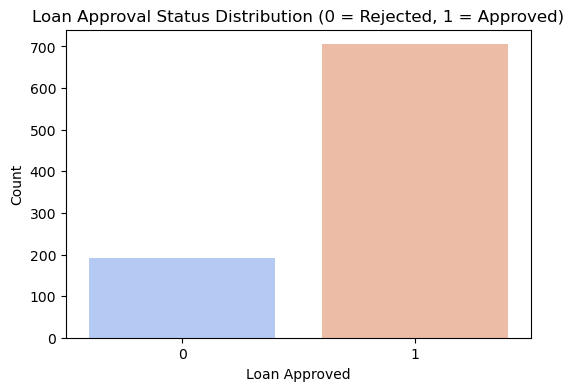

In [18]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="loan_approved", palette="coolwarm")
plt.title("Loan Approval Status Distribution (0 = Rejected, 1 = Approved)")
plt.xlabel("Loan Approved")
plt.ylabel("Count")
plt.show()

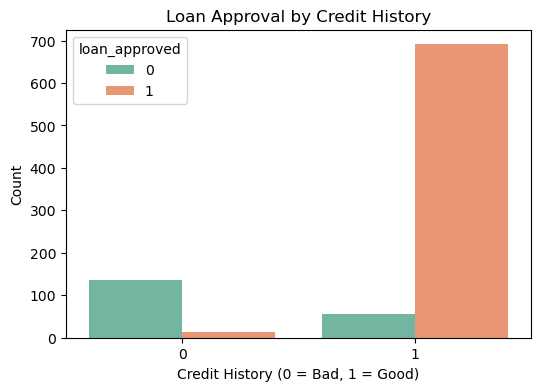

In [19]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="credit_history", hue="loan_approved", palette="Set2")
plt.title("Loan Approval by Credit History")
plt.xlabel("Credit History (0 = Bad, 1 = Good)")
plt.ylabel("Count")
plt.show()

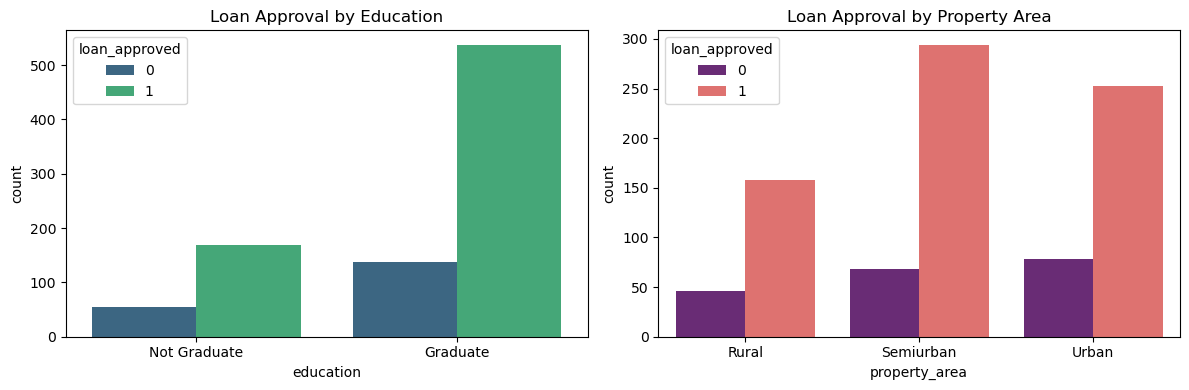

In [20]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.countplot(data=df, x="education", hue="loan_approved", palette="viridis")
plt.title("Loan Approval by Education")

plt.subplot(1, 2, 2)
sns.countplot(data=df, x="property_area", hue="loan_approved", palette="magma")
plt.title("Loan Approval by Property Area")
plt.tight_layout()
plt.show()

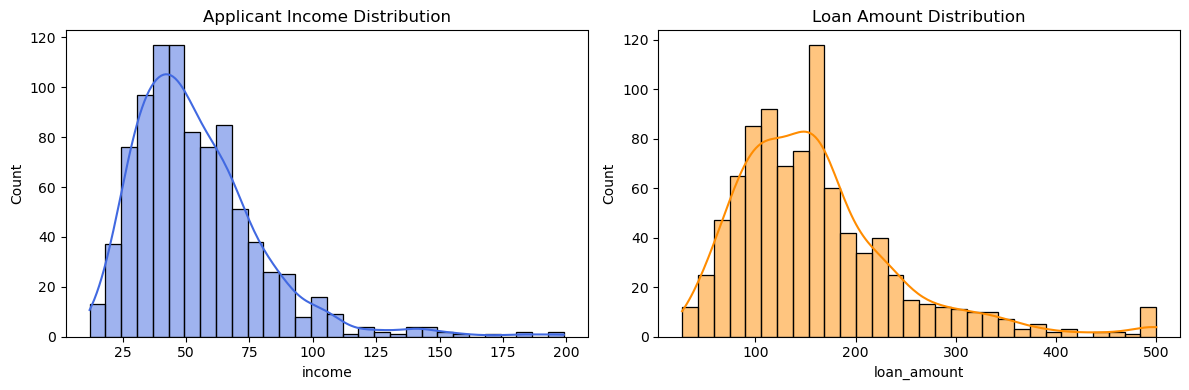

In [21]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(data=df, x="income", kde=True, bins=30, color="royalblue")
plt.title("Applicant Income Distribution")

plt.subplot(1, 2, 2)
sns.histplot(data=df, x="loan_amount", kde=True, bins=30, color="darkorange")
plt.title("Loan Amount Distribution")
plt.tight_layout()
plt.show()

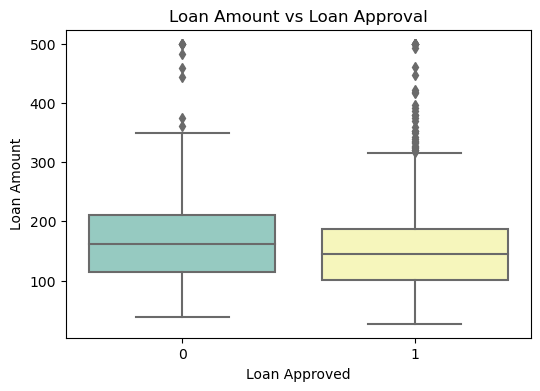

In [22]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="loan_approved", y="loan_amount", palette="Set3")
plt.title("Loan Amount vs Loan Approval")
plt.xlabel("Loan Approved")
plt.ylabel("Loan Amount")
plt.show()

In [23]:
corr = df.corr(numeric_only=True)
print(corr)

                loan_approved  dependents       age    income  loan_amount  \
loan_approved        1.000000   -0.038680 -0.050687 -0.057237    -0.102569   
dependents          -0.038680    1.000000 -0.026787  0.029855     0.039598   
age                 -0.050687   -0.026787  1.000000  0.044924     0.041396   
income              -0.057237    0.029855  0.044924  1.000000     0.869881   
loan_amount         -0.102569    0.039598  0.041396  0.869881     1.000000   
credit_history       0.756707   -0.009889 -0.010253 -0.066373    -0.038937   

                credit_history  
loan_approved         0.756707  
dependents           -0.009889  
age                  -0.010253  
income               -0.066373  
loan_amount          -0.038937  
credit_history        1.000000  


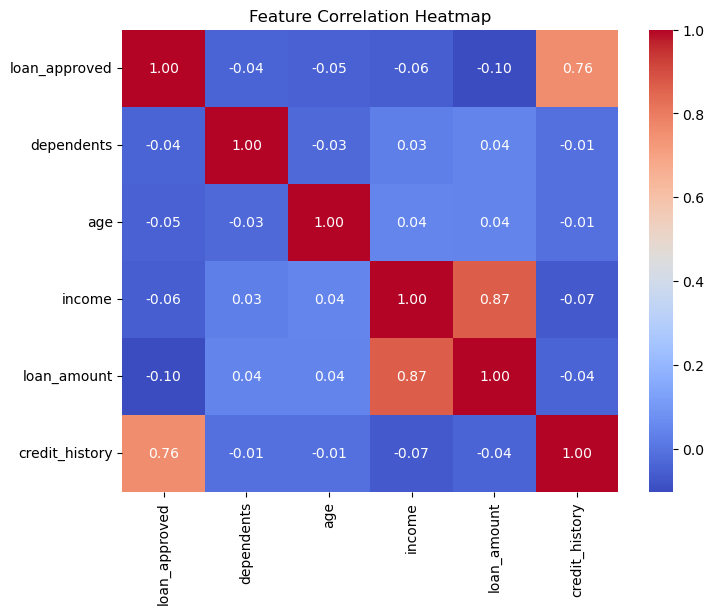

In [24]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

## Encoding Categorical Columns (`LabelEncoder`) & Casting to `int`

In [25]:
from sklearn.preprocessing import LabelEncoder

In [26]:
le = LabelEncoder()

In [27]:
df["gender"] = le.fit_transform(df["gender"])
df["married"] = le.fit_transform(df["married"])
df["education"] = le.fit_transform(df["education"])
df["property_area"] = le.fit_transform(df["property_area"])

In [28]:
df.head()

,loan_approved,gender,married,dependents,education,age,income,loan_amount,credit_history,property_area
0,1,1,1,0,1,37.000000,82.0,332.0,1,0
1,1,0,1,0,0,25.000000,56.0,209.0,1,0
2,1,0,1,0,0,30.000000,87.0,334.0,1,1
3,1,1,1,0,0,27.000000,56.0,175.0,0,1
4,1,1,1,0,0,35.222086,29.0,110.0,1,0


In [29]:
df = df.astype(int)

In [30]:
df.head()

,loan_approved,gender,married,dependents,education,age,income,loan_amount,credit_history,property_area
0,1,1,1,0,1,37,82,332,1,0
1,1,0,1,0,0,25,56,209,1,0
2,1,0,1,0,0,30,87,334,1,1
3,1,1,1,0,0,27,56,175,0,1
4,1,1,1,0,0,35,29,110,1,0


## Splitting Features (`x`) and Target (`y`)

In [31]:
x = df.drop(columns=["loan_approved"])

In [32]:
y = df["loan_approved"]

In [33]:
x.shape

(897, 9)

In [34]:
y.shape

(897,)

In [35]:
from sklearn.model_selection import train_test_split

In [36]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2,stratify=y,random_state=42)

## 1. Logistic Regression

In [37]:
from sklearn.linear_model import LogisticRegression

In [38]:
model = LogisticRegression(max_iter=500)

In [39]:
model.fit(x_train, y_train)

LogisticRegression(max_iter=500)

In [40]:
pred = model.predict(x_test)

In [41]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [42]:
acc = accuracy_score(y_test, pred)
print(acc)

0.9333333333333333


In [43]:
cm = confusion_matrix(y_test, pred)
print(cm)

[[ 30   9]
 [  3 138]]


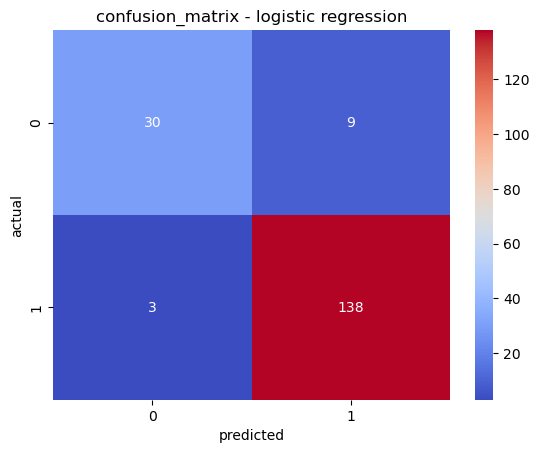

In [44]:
sns.heatmap(cm, annot=True, cmap="coolwarm", fmt="d")
plt.title("confusion_matrix - logistic regression")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.show()

In [45]:
cr = classification_report(y_test, pred)
print(cr)

              precision    recall  f1-score   support

           0       0.91      0.77      0.83        39
           1       0.94      0.98      0.96       141

    accuracy                           0.93       180
   macro avg       0.92      0.87      0.90       180
weighted avg       0.93      0.93      0.93       180



## Feature Scaling (`StandardScaler`) & 2. K-Nearest Neighbors (KNN)

In [46]:
from sklearn.preprocessing import StandardScaler

In [47]:
st = StandardScaler()

In [48]:
x_train_scaled = st.fit_transform(x_train)
x_test_scaled = st.transform(x_test)

In [49]:
from sklearn.neighbors import KNeighborsClassifier

In [50]:
knn_model = KNeighborsClassifier(n_neighbors=5)

In [51]:
knn_model.fit(x_train_scaled, y_train)

KNeighborsClassifier()

In [52]:
knn_pred = knn_model.predict(x_test_scaled)

In [53]:
ac_K = accuracy_score(y_test, knn_pred)
print(ac_K)

0.9277777777777778


In [54]:
cm_K = confusion_matrix(y_test, knn_pred)
print(cm_K)

[[ 30   9]
 [  4 137]]


In [55]:
cr_K = classification_report(y_test, knn_pred)
print(cr_K)

              precision    recall  f1-score   support

           0       0.88      0.77      0.82        39
           1       0.94      0.97      0.95       141

    accuracy                           0.93       180
   macro avg       0.91      0.87      0.89       180
weighted avg       0.93      0.93      0.93       180



In [56]:
knn_model_7 = KNeighborsClassifier(n_neighbors=7)

In [57]:
knn_model_7.fit(x_train_scaled, y_train)

KNeighborsClassifier(n_neighbors=7)

In [58]:
knn_pred_7 = knn_model_7.predict(x_test_scaled)

In [59]:
ac_k_7 = accuracy_score(y_test, knn_pred_7)
print(ac_k_7)

0.9333333333333333


In [60]:
cm_K_7 = confusion_matrix(y_test, knn_pred_7)
print(cm_K_7)

[[ 30   9]
 [  3 138]]


In [61]:
cr_K_7 = classification_report(y_test, knn_pred_7)
print(cr_K_7)

              precision    recall  f1-score   support

           0       0.91      0.77      0.83        39
           1       0.94      0.98      0.96       141

    accuracy                           0.93       180
   macro avg       0.92      0.87      0.90       180
weighted avg       0.93      0.93      0.93       180



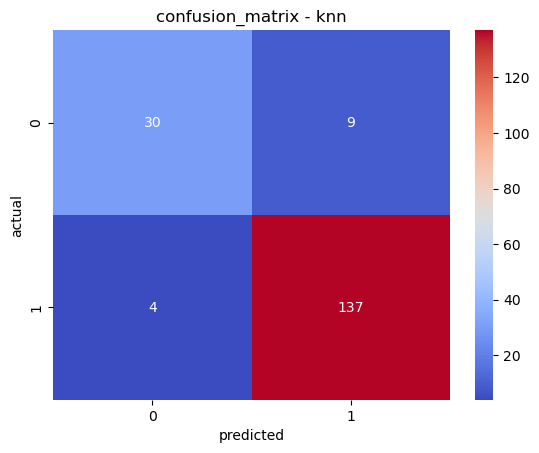

In [62]:
sns.heatmap(cm_K, annot=True, cmap="coolwarm", fmt="d")
plt.title("confusion_matrix - knn")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.show()

## 3. Support Vector Machine (SVM)

In [63]:
from sklearn.svm import SVC

In [64]:
model_svc = SVC(kernel="rbf")

In [65]:
model_svc.fit(x_train_scaled, y_train)

SVC()

In [66]:
svm_pred = model_svc.predict(x_test_scaled)

In [67]:
ac_svm = accuracy_score(y_test, svm_pred)
print(ac_svm)

0.9333333333333333


In [68]:
cm_svm = confusion_matrix(y_test, svm_pred)
print(cm_svm)

[[ 30   9]
 [  3 138]]


In [69]:
cr_svm = classification_report(y_test, svm_pred)
print(cr_svm)

              precision    recall  f1-score   support

           0       0.91      0.77      0.83        39
           1       0.94      0.98      0.96       141

    accuracy                           0.93       180
   macro avg       0.92      0.87      0.90       180
weighted avg       0.93      0.93      0.93       180



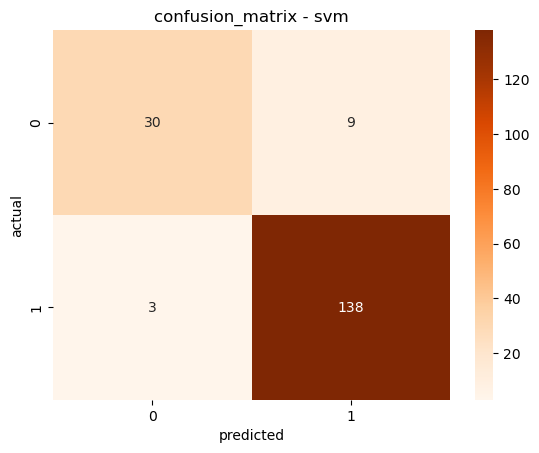

In [70]:
sns.heatmap(cm_svm, annot=True, cmap="Oranges", fmt="d")
plt.title("confusion_matrix - svm")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.show()

## 4. Gaussian Naive Bayes

In [71]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()

In [72]:
nb.fit(x_train, y_train)

GaussianNB()

In [73]:
y_pred_nb = nb.predict(x_test)

In [74]:
acc3 = accuracy_score(y_test, y_pred_nb)
print(acc3)

0.9333333333333333


In [75]:
cm3 = confusion_matrix(y_test, y_pred_nb)
print(cm3)

[[ 30   9]
 [  3 138]]


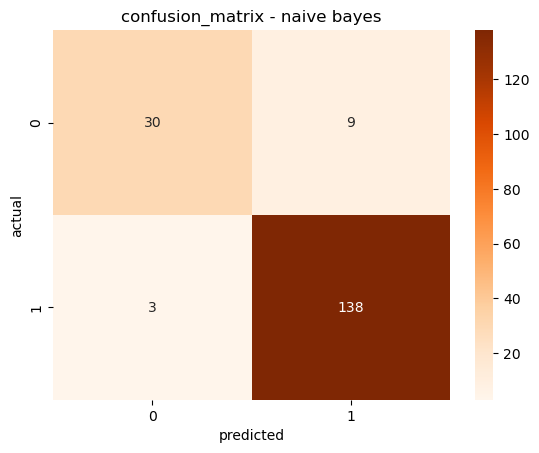

In [76]:
sns.heatmap(cm3, annot=True, cmap="Oranges", fmt="d")
plt.title("confusion_matrix - naive bayes")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.show()

In [77]:
cr3 = classification_report(y_test, y_pred_nb)
print(cr3)

              precision    recall  f1-score   support

           0       0.91      0.77      0.83        39
           1       0.94      0.98      0.96       141

    accuracy                           0.93       180
   macro avg       0.92      0.87      0.90       180
weighted avg       0.93      0.93      0.93       180



## 5. Decision Tree Classifier

In [78]:
from sklearn.tree import DecisionTreeClassifier

In [79]:
dt = DecisionTreeClassifier(random_state=78)

In [80]:
dt.fit(x_train, y_train)

DecisionTreeClassifier(random_state=78)

In [81]:
y_pred_dt = dt.predict(x_test)

In [82]:
acc5 = accuracy_score(y_test, y_pred_dt)
print(acc5)

0.85


In [83]:
cm_dt = confusion_matrix(y_test, y_pred_dt)
print(cm_dt)

[[ 27  12]
 [ 15 126]]


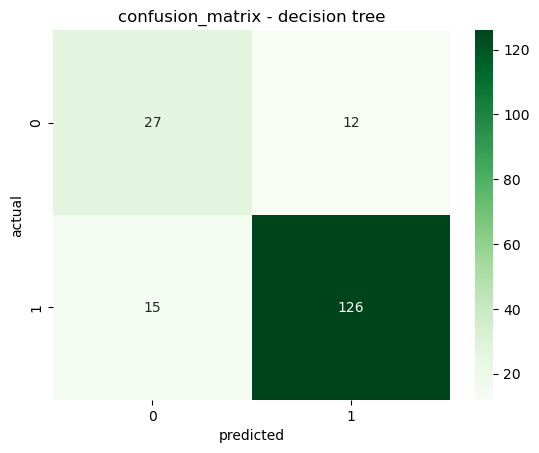

In [84]:
sns.heatmap(cm_dt, annot=True, cmap="Greens", fmt="d")
plt.title("confusion_matrix - decision tree")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.show()

In [85]:
cr4=classification_report(y_test,y_pred_dt)
print(cr4)

              precision    recall  f1-score   support

           0       0.64      0.69      0.67        39
           1       0.91      0.89      0.90       141

    accuracy                           0.85       180
   macro avg       0.78      0.79      0.78       180
weighted avg       0.85      0.85      0.85       180



## 6. Random Forest Classifier

In [86]:
from sklearn.ensemble import RandomForestClassifier

In [87]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)

In [88]:
rf.fit(x_train, y_train)

RandomForestClassifier(random_state=42)

In [89]:
y_pred_rf = rf.predict(x_test)

In [90]:
acc_rf = accuracy_score(y_test, y_pred_rf)
print(acc_rf)

0.9333333333333333


In [91]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
print(cm_rf)

[[ 30   9]
 [  3 138]]


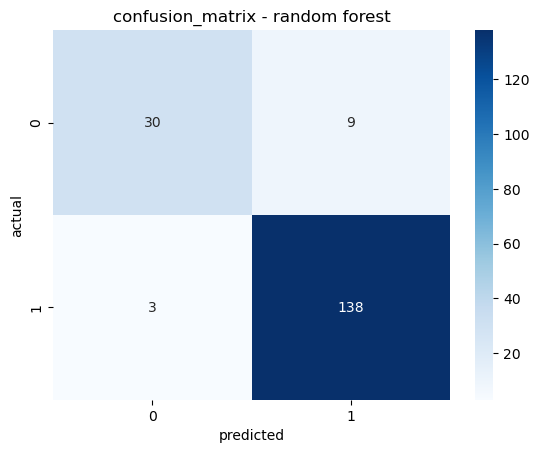

In [92]:
sns.heatmap(cm_rf, annot=True, cmap="Blues", fmt="d")
plt.title("confusion_matrix - random forest")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.show()

In [93]:
cr_rf = classification_report(y_test, y_pred_rf)
print(cr_rf)

              precision    recall  f1-score   support

           0       0.91      0.77      0.83        39
           1       0.94      0.98      0.96       141

    accuracy                           0.93       180
   macro avg       0.92      0.87      0.90       180
weighted avg       0.93      0.93      0.93       180



## 7. Gradient Boosting Classifier

0.9166666666666666
[[ 29  10]
 [  5 136]]


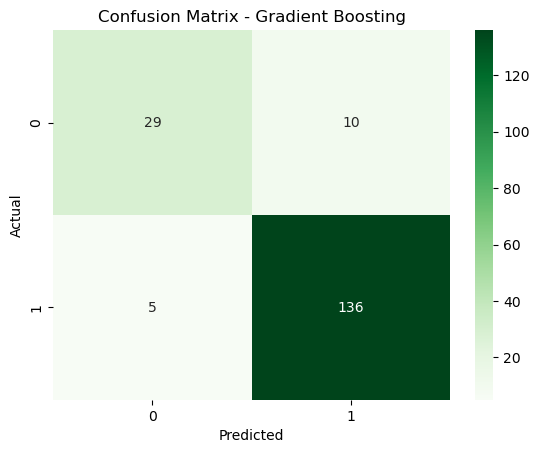

              precision    recall  f1-score   support

           0       0.85      0.74      0.79        39
           1       0.93      0.96      0.95       141

    accuracy                           0.92       180
   macro avg       0.89      0.85      0.87       180
weighted avg       0.91      0.92      0.91       180



In [94]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42)

gb.fit(x_train, y_train)

y_pred_gb = gb.predict(x_test)

acc_gb = accuracy_score(y_test, y_pred_gb)
print(acc_gb)

cm_gb = confusion_matrix(y_test, y_pred_gb)
print(cm_gb)

sns.heatmap(cm_gb, annot=True, cmap="Greens", fmt="d")
plt.title("Confusion Matrix - Gradient Boosting")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

cr_gb = classification_report(y_test, y_pred_gb)
print(cr_gb)

## 8. AdaBoost Classifier

0.9333333333333333
[[ 30   9]
 [  3 138]]


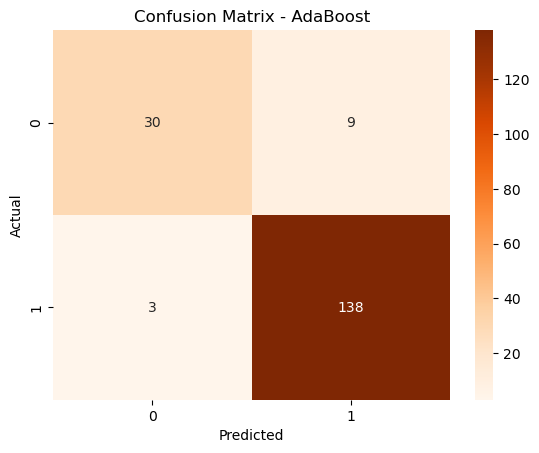

              precision    recall  f1-score   support

           0       0.91      0.77      0.83        39
           1       0.94      0.98      0.96       141

    accuracy                           0.93       180
   macro avg       0.92      0.87      0.90       180
weighted avg       0.93      0.93      0.93       180



In [95]:
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(n_estimators=50, random_state=42)

ada.fit(x_train, y_train)

y_pred_ada = ada.predict(x_test)

acc_ada = accuracy_score(y_test, y_pred_ada)
print(acc_ada)

cm_ada = confusion_matrix(y_test, y_pred_ada)
print(cm_ada)

sns.heatmap(cm_ada, annot=True, cmap="Oranges", fmt="d")
plt.title("Confusion Matrix - AdaBoost")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

cr_ada = classification_report(y_test, y_pred_ada)
print(cr_ada)

## 9. XGBoost Classifier

In [96]:
from xgboost import XGBClassifier

In [97]:
xgb = XGBClassifier(n_estimators=10 ,random_state=42)

In [98]:
xgb.fit(x_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=10,
              n_jobs=None, num_parallel_tree=None, ...)

In [99]:
y_pred_xgb = xgb.predict(x_test)

In [100]:
acc_xgb = accuracy_score(y_test, y_pred_xgb)
print(acc_xgb)

0.9333333333333333


In [101]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
print(cm_xgb)

[[ 30   9]
 [  3 138]]


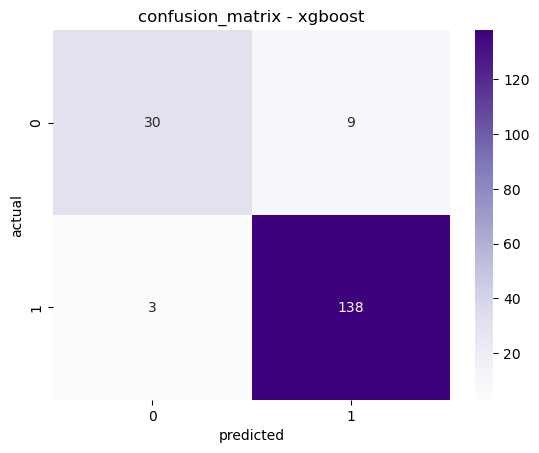

In [102]:
sns.heatmap(cm_xgb, annot=True, cmap="Purples", fmt="d")
plt.title("confusion_matrix - xgboost")
plt.xlabel("predicted")
plt.ylabel("actual")
plt.show()

In [103]:
cr_xgb = classification_report(y_test, y_pred_xgb)
print(cr_xgb)

              precision    recall  f1-score   support

           0       0.91      0.77      0.83        39
           1       0.94      0.98      0.96       141

    accuracy                           0.93       180
   macro avg       0.92      0.87      0.90       180
weighted avg       0.93      0.93      0.93       180



## Model Evaluation

The models are evaluated using accuracy, confusion matrices, precision, recall, and F1-score.

Since `0` represents rejected applications and `1` represents approved applications, recall for class `0` is also important. It shows how many actual rejected applications the model correctly identifies. Therefore, the models should not be compared using accuracy alone.

## Final Model Comparison Summary

In [104]:
summary_df = pd.DataFrame({
    "Model": [
        "Logistic Regression", "KNN (k=5)", "KNN (k=7)", "SVM (RBF)",
        "Naive Bayes", "Decision Tree", "Random Forest",
        "Gradient Boosting", "AdaBoost", "XGBoost"
    ],
    "Accuracy": [
        acc, ac_K, ac_k_7, ac_svm, acc3, acc5, acc_rf,
        acc_gb, acc_ada, acc_xgb
    ]
}).sort_values(by="Accuracy", ascending=False).reset_index(drop=True)
summary_df

,Model,Accuracy
0,Logistic Regression,0.933333
1,KNN (k=7),0.933333
2,SVM (RBF),0.933333
3,Naive Bayes,0.933333
4,Random Forest,0.933333
5,AdaBoost,0.933333
6,XGBoost,0.933333
7,KNN (k=5),0.927778
8,Gradient Boosting,0.916667
9,Decision Tree,0.850000


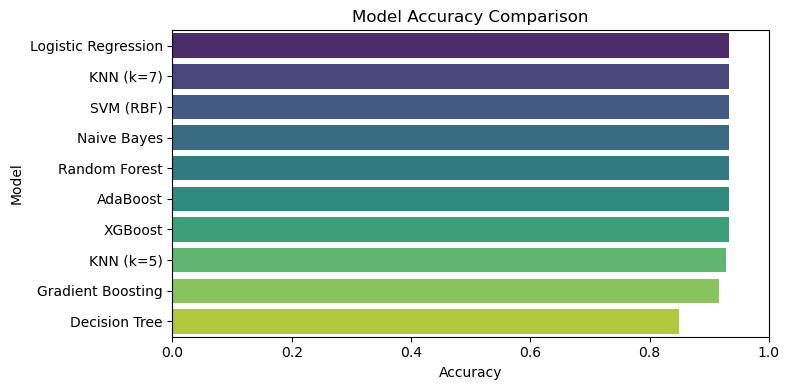

In [105]:
plt.figure(figsize=(8, 4))
sns.barplot(data=summary_df, x="Accuracy", y="Model", palette="viridis")
plt.title("Model Accuracy Comparison")
plt.xlim(0, 1.0)
plt.tight_layout()
plt.show()

## Conclusion

This project explored a bank loan approval dataset through Exploratory Data Analysis (EDA) and applied multiple classification algorithms to predict loan approval outcomes.

The models were evaluated using accuracy, confusion matrices, precision, recall, and F1-score. The comparison shows why model performance should not be judged by accuracy alone, especially when the target classes are imbalanced.

Overall, this project provided practical experience in data exploration, data preprocessing, classification algorithms, and model evaluation.